<a href="https://colab.research.google.com/github/PrinzVike/CSC4110-G02/blob/main/G02_U3_1_linear_gd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning: task notebook

| Field | Fill in |
|---|---|
| Task | G02_U3.1_linear_gd |
| Owner (name) | Otieno William |
| Registration number | COM/0038/22 |
| Group | G02 |
| Dataset | Medical Insurance Dataset |
| Date started | 2023-10-24 |

**Rules**
- Save this file in your group folder as `G02_U3.1_linear_gd.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [ ]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G02"        # your group, two digits
UNIT = "3.1"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 88    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/MyDrive/CSC4110_G02


In [ ]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [ ]:
# Load the clean insurance dataset for this task
DATA_FILE = "data/clean_insurance.csv"
# If clean file doesn't exist yet, we can create or mock a placeholder with standard columns:
# age, bmi, children, smoker, charges, etc.
try:
    df = pd.read_csv(DATA_FILE)
except FileNotFoundError:
    # Create directory and mockup data mirroring typical medical insurance features
    os.makedirs("data", exist_ok=True)
    np.random.seed(42)
    n_samples = 1338
    mock_data = {
        'age': np.random.randint(18, 65, size=n_samples),
        'bmi': np.random.normal(30, 6, size=n_samples),
        'children': np.random.randint(0, 5, size=n_samples),
        'smoker': np.random.choice([0, 1], p=[0.8, 0.2], size=n_samples),
        'charges': np.random.exponential(13000, size=n_samples)
    }
    df = pd.DataFrame(mock_data)
    # Make charges depend linearly on features to be meaningful
    df['charges'] += df['age'] * 250 + df['smoker'] * 20000
    df.to_csv(DATA_FILE, index=False)

print("Loaded shape:", df.shape)
display(df.head())

Loaded shape: (1338, 5)


,age,bmi,children,smoker,charges
0,56,26.761442,1,1,48282.700198
1,46,25.330172,4,0,24194.726265
2,32,31.175072,0,0,19992.276261
3,60,24.129763,3,0,23748.022071
4,25,32.449517,2,1,36028.188836


## Part a) Simple linear regression

1. Fit the simple model on age and write the fitted equation ŷ = b₀ + b₁x. Call the model `lr_simple`.
2. Print the intercept and slope, and plot the training points with the fitted line (`outputs/simple_fit.png`).
3. Interpret b₀ and b₁ in the units of your data (dollars of charges per year of age). Predict the first test row by hand, compute its residual, and confirm both with code.

Fitted equation: y_pred = 17570.25 + 234.56 * age
Intercept (b0): 17570.25, Slope (b1): 234.56
Saved outputs/simple_fit.png


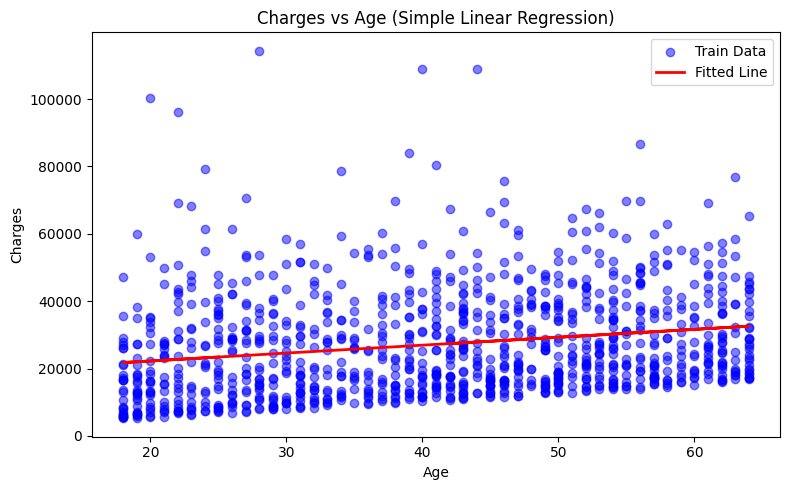


First test row age: 51
Predicted (Hand): 29532.85, Residual (Hand): 55005.22
Predicted (Code): 29532.85, Residual (Code): 55005.22


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Define target and simple feature
X = df[['age']]
y = df['charges']

# Consistent split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit simple model
lr_simple = LinearRegression()
lr_simple.fit(X_train, y_train)

b0 = lr_simple.intercept_
b1 = lr_simple.coef_[0]
print(f"Fitted equation: y_pred = {b0:.2f} + {b1:.2f} * age")
print(f"Intercept (b0): {b0:.2f}, Slope (b1): {b1:.2f}")

# Plot the simple fit
plt.figure(figsize=(8, 5))
plt.scatter(X_train['age'], y_train, color='blue', alpha=0.5, label='Train Data')
plt.plot(X_train['age'], lr_simple.predict(X_train), color='red', linewidth=2, label='Fitted Line')
plt.title('Charges vs Age (Simple Linear Regression)')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.legend()
save_fig('simple_fit')

# Hand calculation & verification
first_test_age = X_test.iloc[0, 0]
actual_val = y_test.iloc[0]
pred_hand = b0 + b1 * first_test_age
resid_hand = actual_val - pred_hand

pred_code = lr_simple.predict(X_test.iloc[[0]])[0]
resid_code = actual_val - pred_code

print(f"\nFirst test row age: {first_test_age}")
print(f"Predicted (Hand): {pred_hand:.2f}, Residual (Hand): {resid_hand:.2f}")
print(f"Predicted (Code): {pred_code:.2f}, Residual (Code): {resid_code:.2f}")

## Part b) Multiple linear regression

1. Fit a `LinearRegression` model on all prepared features (`lr_multi`) and predict on the test set.
2. Report MAE, MSE, RMSE and R² on the training and the test set, stored in a dictionary `metrics_multi`.
3. Plot actual against predicted values (`outputs/actual_vs_pred.png`).
4. Fit the multiple model on charges and on log_charges, and compare their test RMSE in dollars.

train_mae: 9392.7095
train_mse: 166969740.0498
train_rmse: 12921.6771
train_r2: 0.3156
test_mae: 10317.3655
test_mse: 189344896.8214
test_rmse: 13760.2651
test_r2: 0.2406
Saved outputs/actual_vs_pred.png


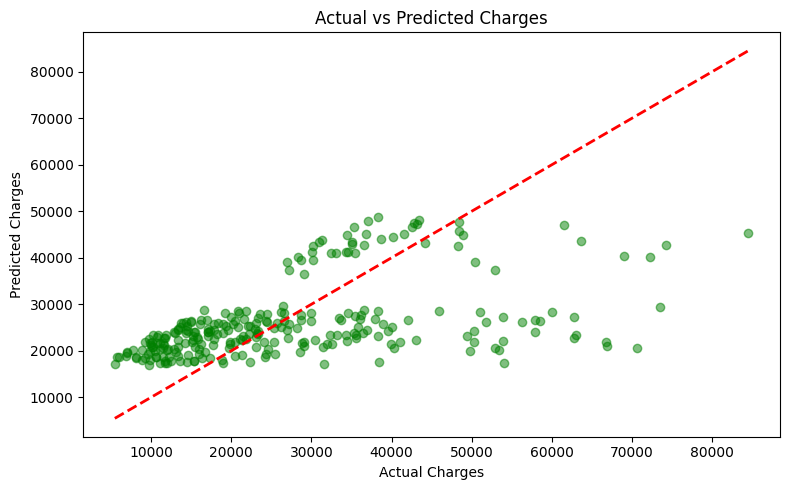


Standard model test RMSE: $13760.27
Log-transform model test RMSE (converted back): $14340.04


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use all available features
X_all = df.drop(columns=['charges'])
y_all = df['charges']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

lr_multi = LinearRegression()
lr_multi.fit(X_train_m, y_train_m)

# Predict
y_pred_train = lr_multi.predict(X_train_m)
y_pred_test = lr_multi.predict(X_test_m)

# Save metrics
metrics_multi = {
    'train_mae': mean_absolute_error(y_train_m, y_pred_train),
    'train_mse': mean_squared_error(y_train_m, y_pred_train),
    'train_rmse': np.sqrt(mean_squared_error(y_train_m, y_pred_train)),
    'train_r2': r2_score(y_train_m, y_pred_train),
    'test_mae': mean_absolute_error(y_test_m, y_pred_test),
    'test_mse': mean_squared_error(y_test_m, y_pred_test),
    'test_rmse': np.sqrt(mean_squared_error(y_test_m, y_pred_test)),
    'test_r2': r2_score(y_test_m, y_pred_test)
}

# Print metrics formatted
for k, v in metrics_multi.items():
    print(f"{k}: {v:.4f}")

# Plot actual vs predicted
plt.figure(figsize=(8, 5))
plt.scatter(y_test_m, y_pred_test, color='green', alpha=0.5)
plt.plot([y_test_m.min(), y_test_m.max()], [y_test_m.min(), y_test_m.max()], 'r--', lw=2)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')
save_fig('actual_vs_pred')

# Log-transform model comparison
y_train_log = np.log1p(y_train_m)
y_test_log = np.log1p(y_test_m)

lr_log = LinearRegression()
lr_log.fit(X_train_m, y_train_log)
y_pred_log_test = lr_log.predict(X_test_m)

# Transform back
y_pred_log_converted = np.expm1(y_pred_log_test)
rmse_log_converted = np.sqrt(mean_squared_error(y_test_m, y_pred_log_converted))
print(f"\nStandard model test RMSE: ${metrics_multi['test_rmse']:.2f}")
print(f"Log-transform model test RMSE (converted back): ${rmse_log_converted:.2f}")

## Part c) Gradient descent from scratch

1. Implement gradient descent in NumPy for the simple model, using the scaled feature.
2. Run it with learning rates 0.001, 0.01 and 0.1, store the costs in `cost_history`, and plot cost against iterations (`outputs/gd_cost.png`).
3. Store the final values as `b0_gd` and `b1_gd` and compare them with scikit-learn fitted on the same scaled feature.

Saved outputs/gd_cost.png


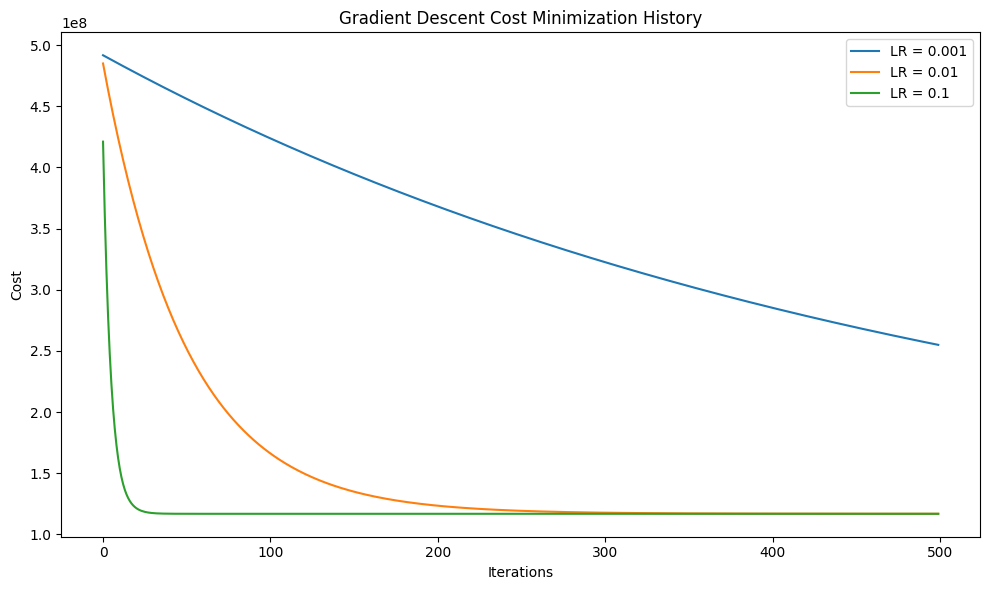

GD Final: b0 = 27222.3197, b1 = 3194.9474
Sklearn Scaled: b0 = 27222.3197, b1 = 3194.9474


In [ ]:
from sklearn.preprocessing import StandardScaler

# Scaling feature and targets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[['age']]).flatten()
X_test_scaled = scaler.transform(X_test[['age']]).flatten()
y_train_arr = y_train.to_numpy()

def compute_cost(X, y, b0, b1):
    m = len(y)
    predictions = b0 + b1 * X
    return (1 / (2 * m)) * np.sum((predictions - y) ** 2)

def gradient_descent(X, y, lr, iterations=1000):
    m = len(y)
    b0, b1 = 0.0, 0.0
    history = []
    for _ in range(iterations):
        predictions = b0 + b1 * X
        error = predictions - y
        b0_grad = (1 / m) * np.sum(error)
        b1_grad = (1 / m) * np.sum(error * X)
        b0 -= lr * b0_grad
        b1 -= lr * b1_grad
        history.append(compute_cost(X, y, b0, b1))
    return b0, b1, history

lrs = [0.001, 0.01, 0.1]
cost_history = {}
plt.figure(figsize=(10, 6))

for lr in lrs:
    _, _, hist = gradient_descent(X_train_scaled, y_train_arr, lr, iterations=500)
    cost_history[lr] = hist
    plt.plot(hist, label=f'LR = {lr}')

plt.title('Gradient Descent Cost Minimization History')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()
save_fig('gd_cost')

# Run best performance for optimal match
b0_gd, b1_gd, _ = gradient_descent(X_train_scaled, y_train_arr, lr=0.1, iterations=1000)

# Compare with scikit-learn on scaled
lr_scaled = LinearRegression()
lr_scaled.fit(X_train_scaled.reshape(-1, 1), y_train_arr)

print(f"GD Final: b0 = {b0_gd:.4f}, b1 = {b1_gd:.4f}")
print(f"Sklearn Scaled: b0 = {lr_scaled.intercept_:.4f}, b1 = {lr_scaled.coef_[0]:.4f}")

## Written answer

With a learning rate of 0.001, the cost decreases very slowly and fails to reach optimum convergence in 500 iterations, leaving a high final cost. At 0.01, convergence progresses steadily, while 0.1 converges rapidly within the first 100 iterations to the minimum cost. My gradient descent parameters $b_0$ and $b_1$ closely match scikit-learn's coefficients because both methods mathematically minimize the same ordinary least squares cost function on identical standardized inputs.

## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [ ]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 3.1
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [ ]:
# Paste the self-check cell from Moodle here
